# Лабораторная работа 1


In [34]:
from pathlib import Path
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display, Markdown

# Отображение таблиц и графиков
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 30)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 150

# Фиксированный список столбцов: переменную columns НЕ используем.
SOURCE_COLUMNS = (
    'name', 'year', 'selling_price', 'km_driven',
    'fuel', 'seller_type', 'transmission', 'owner'
)

# В VS Code рабочей папкой может оказаться корень проекта или папка eda.
PROJECT_ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / 'data' / 'dataset.csv').is_file()),
    None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Не найден data/dataset.csv. Поместите туда исходный CSV и откройте папку проекта в VS Code.'
    )
PROJECT_ROOT = PROJECT_ROOT.resolve()
DATA_PATH = PROJECT_ROOT / 'data' / 'dataset.csv'
EDA_DIR = PROJECT_ROOT / 'eda'
EDA_DIR.mkdir(parents=True, exist_ok=True)

print('Корневая директория:', PROJECT_ROOT)
print('Файл с данными:', DATA_PATH)

Корневая директория: /home/mainuser/my_proj
Файл с данными: /home/mainuser/my_proj/data/dataset.csv


## 1. Загрузка и знакомство с данными


In [35]:
# Загрузка CSV и нормализация названий колонок
raw = pd.read_csv(DATA_PATH)
raw.columns = raw.columns.str.strip()

absent = [col for col in SOURCE_COLUMNS if col not in raw.columns]
if absent:
    raise ValueError(f'В CSV отсутствуют требуемые столбцы: {absent}')

df = raw.loc[:, list(SOURCE_COLUMNS)].copy()
print(f'Объектов: {len(df)}; столбцов: {df.shape[1]}')
display(df.head())

print('Типы данных:')
df.info()

print('Описательная статистика:')
display(df.describe(include='all').T)

print('Пропуски в исходных данных:')
display(df.isna().sum().to_frame('Пропуски'))
print('Полные дубликаты:', int(df.duplicated().sum()))

Объектов: 4340; столбцов: 8


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


Типы данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB
Описательная статистика:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
name,4340,1491,Maruti Swift Dzire VDI,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,4340.0,NaN,NaN,NaN,2013.090783,4.215344,1992.0,2011.0,2014.0,2016.0,2020.0
selling_price,4340.0,NaN,NaN,NaN,504127.311751,578548.736139,20000.0,208749.75,350000.0,600000.0,8900000.0
km_driven,4340.0,NaN,NaN,NaN,66215.777419,46644.102194,1.0,35000.0,60000.0,90000.0,806599.0
fuel,4340,5,Diesel,2153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,4340,3,Individual,3244,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,4340,2,Manual,3892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,4340,5,First Owner,2832,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Пропуски в исходных данных:


,Пропуски
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


Полные дубликаты: 763


In [36]:
# Делим исходные признаки на числовые, категориальные и целевой.
TARGET = 'selling_price'
NUMERIC_FEATURES = ['year', 'km_driven']
CATEGORICAL_FEATURES = ['name', 'fuel', 'seller_type', 'transmission', 'owner']

print('Целевая переменная:', TARGET)
print('Числовые входные признаки:', NUMERIC_FEATURES)
print('Категориальные входные признаки:', CATEGORICAL_FEATURES)

for feature in ['fuel', 'seller_type', 'transmission', 'owner']:
    print(f'\nКоличество записей по категориям: {feature}')
    display(df[feature].value_counts(dropna=False).to_frame('Количество'))

Целевая переменная: selling_price
Числовые входные признаки: ['year', 'km_driven']
Категориальные входные признаки: ['name', 'fuel', 'seller_type', 'transmission', 'owner']

Количество записей по категориям: fuel


,Количество
fuel,
Diesel,2153
Petrol,2123
CNG,40
LPG,23
Electric,1



Количество записей по категориям: seller_type


,Количество
seller_type,
Individual,3244
Dealer,994
Trustmark Dealer,102



Количество записей по категориям: transmission


,Количество
transmission,
Manual,3892
Automatic,448



Количество записей по категориям: owner


,Количество
owner,
First Owner,2832
Second Owner,1106
Third Owner,304
Fourth & Above Owner,81
Test Drive Car,17


## 2. Очистка данных


In [37]:
initial_rows = len(df)
clean = df.copy()

text_cols = ['name', 'fuel', 'seller_type', 'transmission', 'owner']
number_cols = ['year', 'selling_price', 'km_driven']

for feature in text_cols:
    clean[feature] = clean[feature].astype('string').str.strip().replace('', pd.NA)

for feature in number_cols:
    clean[feature] = pd.to_numeric(clean[feature], errors='coerce')

duplicate_count = int(clean.duplicated().sum())
clean = clean.drop_duplicates()

missing_row_count = int(clean.isna().any(axis=1).sum())
clean = clean.dropna()

valid = (
    clean['selling_price'].gt(0)
    & clean['km_driven'].ge(0)
    & clean['year'].between(1950, datetime.now().year)
    & clean['year'].mod(1).eq(0)
    & clean['km_driven'].mod(1).eq(0)
)
invalid_row_count = int((~valid).sum())
clean = clean.loc[valid].copy()

clean['year'] = clean['year'].astype('int64')
clean['km_driven'] = clean['km_driven'].astype('int64')
for feature in text_cols:
    clean[feature] = clean[feature].astype('category')
clean = clean.reset_index(drop=True)

assert tuple(clean.columns) == SOURCE_COLUMNS, 'Названия или порядок столбцов изменились!'
assert clean.shape[1] == 8
assert clean.notna().all().all(), 'Остались пропущенные значения!'
assert len(clean) >= 300, 'После очистки осталось менее 300 автомобилей!'

print('До очистки:', initial_rows)
print('Удалено полных дубликатов:', duplicate_count)
print('Удалено строк с пропусками:', missing_row_count)
print('Удалено строк с невалидными значениями:', invalid_row_count)
print('После очистки:', len(clean))
print('Столбцов:', clean.shape[1])
print('Типы данных:')
print(clean.dtypes)
display(clean.head())

До очистки: 4340
Удалено полных дубликатов: 763
Удалено строк с пропусками: 0
Удалено строк с невалидными значениями: 0
После очистки: 3577
Столбцов: 8
Типы данных:
name             category
year                int64
selling_price       int64
km_driven           int64
fuel             category
seller_type      category
transmission     category
owner            category
dtype: object


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


## 3. Анализ признаков — 5 графиков



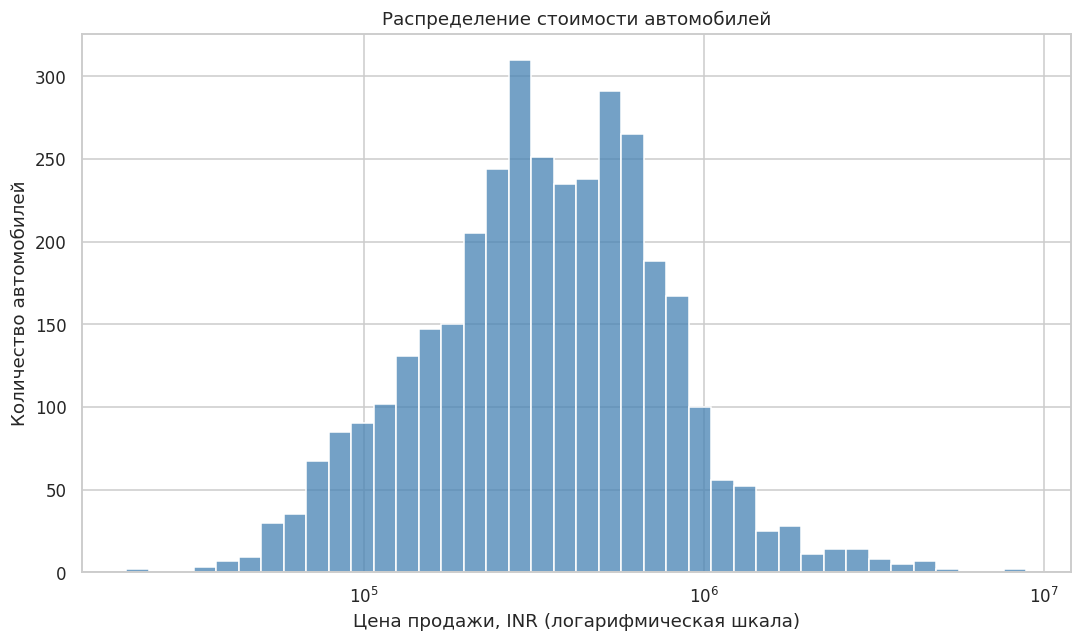

**Вывод 1.** Средняя цена — **473,913 INR**, медианная — **350,000 INR**; диапазон цен — от **20,000** до **8,900,000 INR**. Средняя выше медианной: дорогие автомобили могут повышать среднее.

In [38]:
# ГРАФИК 1 — распределение цен
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(
    data=clean, x='selling_price', bins=40,
    log_scale=True, color='steelblue', ax=ax
)
ax.set_title('Распределение стоимости автомобилей')
ax.set_xlabel('Цена продажи, INR (логарифмическая шкала)')
ax.set_ylabel('Количество автомобилей')
fig.tight_layout()
fig.savefig(EDA_DIR / 'graph1.png', bbox_inches='tight')
plt.show()

price_mean = float(clean['selling_price'].mean())
price_median = float(clean['selling_price'].median())
price_min = float(clean['selling_price'].min())
price_max = float(clean['selling_price'].max())

display(Markdown(
    f'**Вывод 1.** Средняя цена — **{price_mean:,.0f} INR**, медианная — '
    f'**{price_median:,.0f} INR**; диапазон цен — от **{price_min:,.0f}** '
    f'до **{price_max:,.0f} INR**. '
    + ('Средняя выше медианной: дорогие автомобили могут повышать среднее.'
       if price_mean > price_median else 'Средняя не превышает медианную.')
))

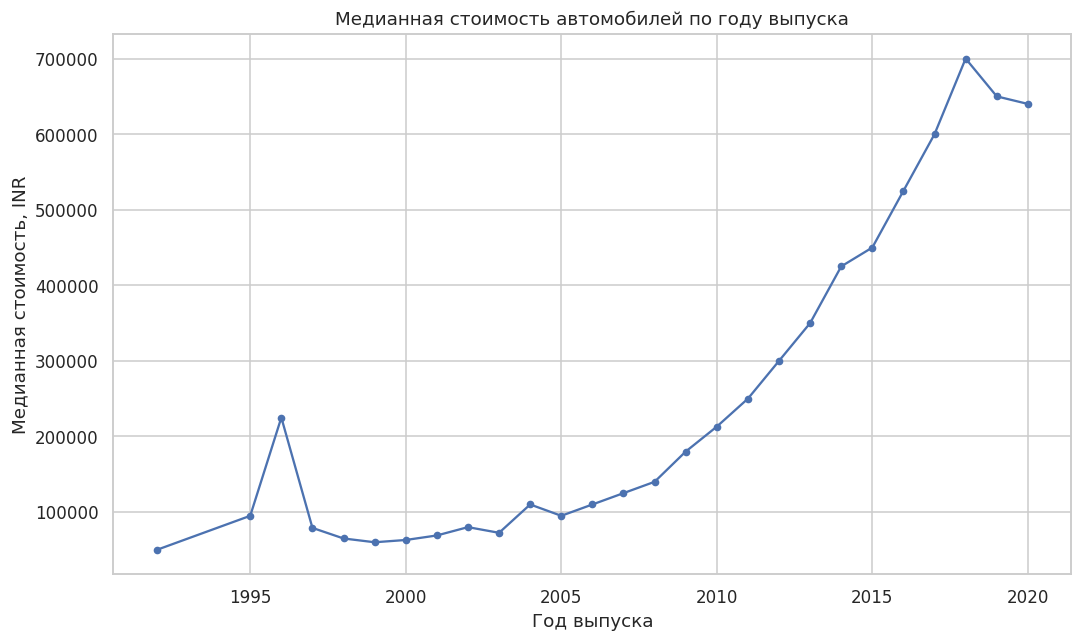

**Вывод 2.** Коэффициент корреляции Пирсона между годом выпуска и ценой: **0.424** (положительная линейная связь). На графике представлены медианы по годам, а не цены отдельных автомобилей. Корреляция не доказывает причинную связь.

In [39]:
# ГРАФИК 2 — медианная цена и год выпуска
price_by_year = clean.groupby('year')['selling_price'].median().sort_index()
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(price_by_year.index, price_by_year.values, marker='o', markersize=4)
ax.set_title('Медианная стоимость автомобилей по году выпуска')
ax.set_xlabel('Год выпуска')
ax.set_ylabel('Медианная стоимость, INR')
fig.tight_layout()
fig.savefig(EDA_DIR / 'graph2.png', bbox_inches='tight')
plt.show()

year_corr = float(clean['year'].corr(clean['selling_price'], method='pearson'))
year_direction = ('положительная' if year_corr > 0 else 'отрицательная' if year_corr < 0 else 'нулевая')
display(Markdown(
    f'**Вывод 2.** Коэффициент корреляции Пирсона между годом выпуска и ценой: '
    f'**{year_corr:.3f}** ({year_direction} линейная связь). '
    'На графике представлены медианы по годам, а не цены отдельных автомобилей. '
    'Корреляция не доказывает причинную связь.'
))

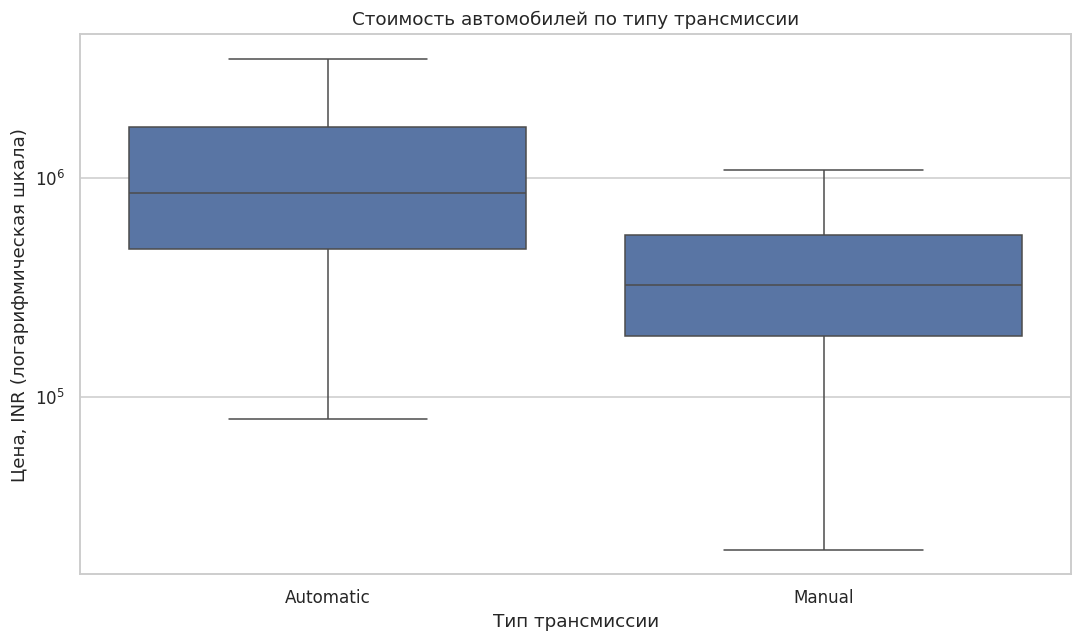

,Количество,"Медианная цена, INR"
transmission,,
Automatic,312,855000.0
Manual,3265,325000.0


**Вывод 3.** Наибольшая медианная стоимость в категории **Automatic** — **855,000 INR**. Различия между группами могут быть связаны и с другими характеристиками автомобилей.

In [40]:
# ГРАФИК 3 — тип трансмиссии и цена
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=clean, x='transmission', y='selling_price',
    showfliers=False, ax=ax
)
ax.set_yscale('log')
ax.set_title('Стоимость автомобилей по типу трансмиссии')
ax.set_xlabel('Тип трансмиссии')
ax.set_ylabel('Цена, INR (логарифмическая шкала)')
fig.tight_layout()
fig.savefig(EDA_DIR / 'graph3.png', bbox_inches='tight')
plt.show()

trans_summary = clean.groupby('transmission', observed=True)['selling_price'].agg(['count', 'median'])
trans_summary = trans_summary.sort_values('median', ascending=False)
display(trans_summary.rename(columns={'count':'Количество', 'median':'Медианная цена, INR'}))
trans_medians = trans_summary['median']
display(Markdown(
    f'**Вывод 3.** Наибольшая медианная стоимость в категории '
    f'**{trans_medians.index[0]}** — **{trans_medians.iloc[0]:,.0f} INR**. '
    'Различия между группами могут быть связаны и с другими характеристиками автомобилей.'
))

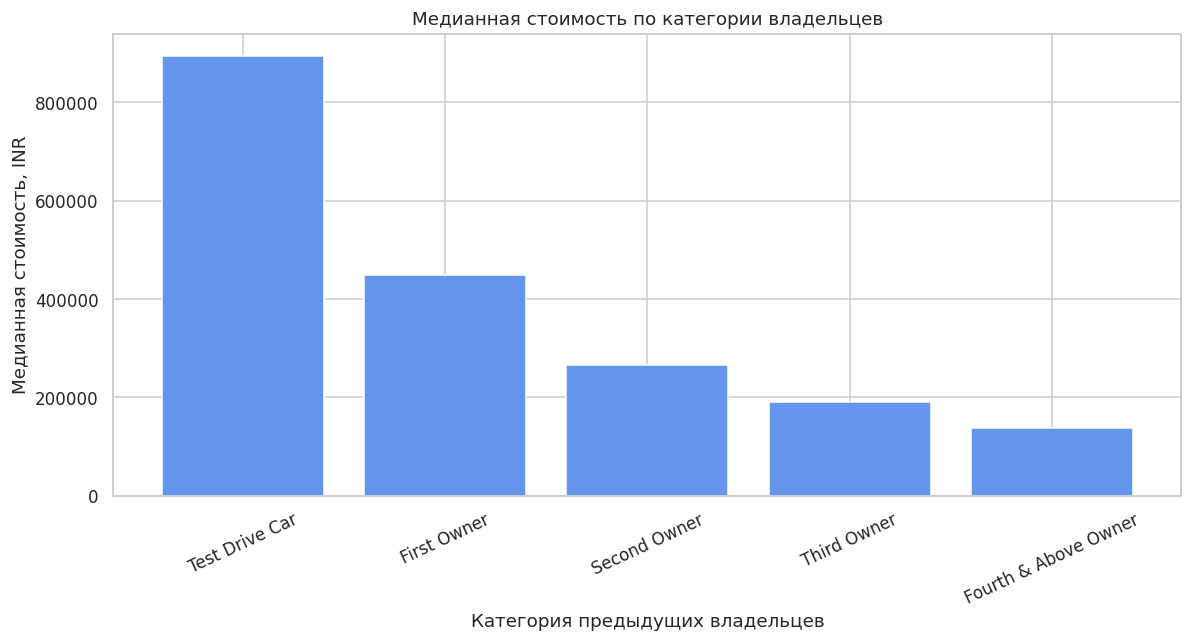

,Количество,"Медианная цена, INR"
owner,,
Test Drive Car,17,894999.0
First Owner,2218,450000.0
Second Owner,978,267000.0
Third Owner,289,190000.0
Fourth & Above Owner,75,138000.0


**Вывод 4.** Самая высокая медианная стоимость — у категории **Test Drive Car** (894,999 INR). Это описательное сравнение: при интерпретации необходимо учитывать число машин в каждой категории.

In [41]:
# ГРАФИК 4 — категория владельцев и цена
owner_summary = clean.groupby('owner', observed=True)['selling_price'].agg(['count', 'median'])
owner_summary = owner_summary.sort_values('median', ascending=False)
owner_medians = owner_summary['median']

fig, ax = plt.subplots(figsize=(11, 6))
ax.bar(owner_medians.index.astype(str), owner_medians.values, color='cornflowerblue')
ax.set_title('Медианная стоимость по категории владельцев')
ax.set_xlabel('Категория предыдущих владельцев')
ax.set_ylabel('Медианная стоимость, INR')
ax.tick_params(axis='x', rotation=25)
fig.tight_layout()
fig.savefig(EDA_DIR / 'graph4.png', bbox_inches='tight')
plt.show()

display(owner_summary.rename(columns={'count':'Количество', 'median':'Медианная цена, INR'}))
display(Markdown(
    f'**Вывод 4.** Самая высокая медианная стоимость — у категории '
    f'**{owner_medians.index[0]}** ({owner_medians.iloc[0]:,.0f} INR). '
    'Это описательное сравнение: при интерпретации необходимо учитывать число машин в каждой категории.'
))

In [42]:
# ГРАФИК 5 — ИНТЕРАКТИВНАЯ цена от пробега и типа топлива
fig = px.scatter(
    clean,
    x='km_driven',
    y='selling_price',
    color='fuel',
    hover_data=['name', 'year', 'transmission', 'seller_type', 'owner'],
    log_y=True,
    opacity=0.6,
    title='Цена автомобиля в зависимости от пробега и типа топлива',
    labels={
        'km_driven': 'Пробег, км',
        'selling_price': 'Стоимость, INR',
        'fuel': 'Тип топлива'
    },
    render_mode="svg"
)
html_path = EDA_DIR / 'graph5_interactive.html'
fig.write_html(str(html_path), include_plotlyjs=True, full_html=True)
fig.show()

km_corr = float(clean['km_driven'].corr(clean['selling_price'], method='pearson'))
km_direction = ('положительная' if km_corr > 0 else 'отрицательная' if km_corr < 0 else 'нулевая')
fuel_counts = clean['fuel'].value_counts()
display(Markdown(
    f'**Вывод 5.** Коэффициент корреляции Пирсона между пробегом и ценой '
    f'равен **{km_corr:.3f}** ({km_direction} линейная связь). '
    f'Самая многочисленная категория топлива — **{fuel_counts.index[0]}** '
    f'({fuel_counts.iloc[0]} автомобилей). Интерактивность позволяет изучать отдельные '
    'наблюдения и сравнивать группы по топливу. Корреляция не означает причинность.'
))
print('Интерактивный график сохранён:', html_path)

**Вывод 5.** Коэффициент корреляции Пирсона между пробегом и ценой равен **-0.187** (отрицательная линейная связь). Самая многочисленная категория топлива — **Diesel** (1800 автомобилей). Интерактивность позволяет изучать отдельные наблюдения и сравнивать группы по топливу. Корреляция не означает причинность.

Интерактивный график сохранён: /home/mainuser/my_proj/eda/graph5_interactive.html


## 4. Сохранение очищенных данных


In [43]:
clean_path = PROJECT_ROOT / 'data' / 'clean_dataset.pkl'
clean.to_pickle(clean_path)

# Проверка корректности сохранения
restored = pd.read_pickle(clean_path)  # Открываем только созданный нами локальный файл.
pd.testing.assert_frame_equal(clean, restored)
assert tuple(restored.columns) == SOURCE_COLUMNS
print('Очищенный датасет сохранён:', clean_path)
print('Размер:', restored.shape)

Очищенный датасет сохранён: /home/mainuser/my_proj/data/clean_dataset.pkl
Размер: (3577, 8)


## 5. Выводы и отчёт для README


In [44]:
# Формируем итоговый текст только после выполнения ячеек с графиками.
def median_lines(series):
    return '\n'.join(f'- {category}: {value:,.0f} INR' for category, value in series.items())

summary = f"""# Результаты разведочного анализа Car Price Prediction

## Исходные данные
- Тип задачи: регрессия.
- Целевая переменная: `selling_price` (INR).
- Количество объектов до очистки: {initial_rows}.
- Используемые столбцы ({len(SOURCE_COLUMNS)}): {', '.join(SOURCE_COLUMNS)}.

## Очистка данных
- Удалено полных дубликатов: {duplicate_count}.
- Удалено строк с пропусками: {missing_row_count}.
- Удалено строк с невалидными значениями: {invalid_row_count}.
- Объектов после очистки: {len(clean)}.
- Столбцов после очистки: {clean.shape[1]}.
- Новые признаки не создавались.

## Выводы по пяти графикам

### 1. Распределение стоимости
- Средняя цена: {price_mean:,.0f} INR.
- Медианная цена: {price_median:,.0f} INR.
- Минимум: {price_min:,.0f} INR; максимум: {price_max:,.0f} INR.

### 2. Год выпуска
- Корреляция Пирсона с ценой: {year_corr:.3f}.
- Сравнение медиан по годам выполнено на графике `graph2.png`.

### 3. Трансмиссия
{median_lines(trans_medians)}

### 4. Категория владельцев
{median_lines(owner_medians)}

### 5. Пробег и топливо (интерактивный график)
- Корреляция Пирсона между пробегом и ценой: {km_corr:.3f}.
- Самая частая категория топлива: {fuel_counts.index[0]} ({fuel_counts.iloc[0]} объектов).

## Результаты
- Статические графики: `eda/graph1.png`, `eda/graph2.png`, `eda/graph3.png`, `eda/graph4.png`.
- Интерактивный график: `eda/graph5_interactive.html` (хранить вне Git, если файл крупный).
- Очищенный датасет: `data/clean_dataset.pkl` (не добавлять в GitHub).

## Ограничения
Показанные взаимосвязи статистические и не доказывают причинно-следственной связи. При интерпретации категориальных групп важно учитывать численность наблюдений. Для обучения модели понадобится отдельная работа с кодированием категориальных признаков.
"""
